<a href="https://colab.research.google.com/github/mohitraj91428-droid/-cset485-assignment1-adultincome-/blob/main/CSET485_Assignment1_AdultIncome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET485: AI and Society - Assignment 1
**Student:** Mohit Raj  
**Enrollment:** S24BCAU0046  
**Seed:** 46  
**Dataset:** Adult Census Income Dataset

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Set random seed
SEED = 46

## 0. Data Preprocessing

In [2]:
# Load data from UCI repository
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

cols = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

train_df = pd.read_csv(data_url, names=cols, skipinitialspace=True)
test_df = pd.read_csv(test_url, names=cols, skipinitialspace=True, skiprows=1)

# Clean outcome column
test_df['income'] = test_df['income'].str.rstrip('.')
df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

# Missing values handling
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)

# Deduplication
df.drop_duplicates(inplace=True)

# Clean rare categories
df = df[df['workclass'] != 'Without-pay']
df['occupation'] = df['occupation'].replace('Armed-Forces', 'Protective-serv')

# Binary targets and features
df['target'] = (df['income'] == '>50K').astype(int)
df['male'] = (df['sex'] == 'Male').astype(int)
df['married'] = df['marital_status'].str.startswith('Married').astype(int)
df['native_us'] = (df['native_country'] == 'United-States').astype(int)

# One-hot encoding (baseline references: White, Private, Adm-clerical)
df = pd.get_dummies(df, columns=['race', 'workclass', 'occupation'], drop_first=False)
baseline_cols = ['race_White', 'workclass_Private', 'occupation_Adm-clerical']
df.drop(columns=[c for c in baseline_cols if c in df.columns], inplace=True)

# Log transforms
df['log_capital_gain'] = np.log1p(df['capital_gain'])
df['log_capital_loss'] = np.log1p(df['capital_loss'])

# Drop redundant or collinear columns
drop_cols = ['fnlwgt', 'education', 'relationship', 'marital_status', 'sex', 'native_country', 'income', 'capital_gain', 'capital_loss']
df_model = df.drop(columns=drop_cols)

# Train-Test Split (70/30, seed = 46)
X = df_model.drop(columns=['target'])
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Standardisation on numeric features
num_cols = ['age', 'education_num', 'hours_per_week', 'log_capital_gain', 'log_capital_loss']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Add constant for statsmodels
X_train_sm = sm.add_constant(X_train_scaled.astype(float))
X_test_sm = sm.add_constant(X_test_scaled.astype(float))

## Part 1: Two Models, Two Cut-offs

In [3]:
# Model A: Linear Probability Model (OLS)
model_a = sm.OLS(y_train, X_train_sm).fit()
preds_a_raw = model_a.predict(X_test_sm)
thresh_a = preds_a_raw.median()
preds_a = (preds_a_raw >= thresh_a).astype(int)

# Model B: Logistic Regression
model_b = sm.Logit(y_train, X_train_sm).fit(disp=False)
preds_b_raw = model_b.predict(X_test_sm)
preds_b = (preds_b_raw >= 0.50).astype(int)

# Confusion matrix
cm_ab = pd.crosstab(preds_a, preds_b, rownames=['Model A (Median)'], colnames=['Model B (0.5)'])
mismatches = np.sum(preds_a != preds_b)
mismatch_pct = (mismatches / len(y_test)) * 100

print("=== PART 1 RESULTS ===")
print("Confusion Matrix:")
print(cm_ab)
print(f"Mismatched Cases: {mismatches} ({mismatch_pct:.2f}%)")

=== PART 1 RESULTS ===
Confusion Matrix:
Model B (0.5)        0     1
Model A (Median)            
0                 6773     0
1                 4070  2704
Mismatched Cases: 4070 (30.04%)


## Part 2.1: Simpson's Paradox Hunt

In [4]:
X_full_sm = sm.add_constant(X.astype(float))
X_full_scaled = X_full_sm.copy()
X_full_scaled[num_cols] = scaler.fit_transform(X_full_sm[num_cols])

# Pooled model
logit_full = sm.Logit(y, X_full_scaled).fit(disp=False)
# Unmarried subgroup
mask_unm = (df['married'] == 0)
logit_unm = sm.Logit(y[mask_unm], X_full_scaled[mask_unm].drop(columns=['married'])).fit(disp=False)
# Married subgroup
mask_mar = (df['married'] == 1)
logit_mar = sm.Logit(y[mask_mar], X_full_scaled[mask_mar].drop(columns=['married'])).fit(disp=False)

print("=== PART 2.1 SIMPSON'S PARADOX ===")
print(f"Everyone male beta: {logit_full.params['male']:.3f} (p={logit_full.pvalues['male']:.4f})")
print(f"Unmarried male beta: {logit_unm.params['male']:.3f} (p={logit_unm.pvalues['male']:.4e})")
print(f"Married male beta: {logit_mar.params['male']:.3f} (p={logit_mar.pvalues['male']:.4e})")

=== PART 2.1 SIMPSON'S PARADOX ===
Everyone male beta: 0.181 (p=0.0000)
Unmarried male beta: 0.631 (p=1.8403e-20)
Married male beta: -0.127 (p=2.0421e-02)


## Part 2.2: Omitted-Variable Bias

In [5]:
model_full = sm.Logit(y, X_full_scaled).fit(disp=False)
model_reduced = sm.Logit(y, X_full_scaled.drop(columns=['married'])).fit(disp=False)

preds_check = ['male', 'race_Black', 'age', 'education_num', 'log_capital_gain', 'hours_per_week']
ovb_table = []

for p in preds_check:
    b_full = model_full.params[p]
    b_red = model_reduced.params[p]
    pct_change = ((b_red - b_full) / abs(b_full)) * 100
    ovb_table.append({'Predictor': p, 'With married': b_full, 'Without': b_red, 'Relative change %': pct_change})

print("=== PART 2.2 OMITTED VARIABLE BIAS ===")
print(pd.DataFrame(ovb_table).to_string(index=False))

=== PART 2.2 OMITTED VARIABLE BIAS ===
       Predictor  With married   Without  Relative change %
            male      0.181169  1.167473         544.411078
      race_Black     -0.195408 -0.392263        -100.740676
             age      0.381404  0.551701          44.650035
   education_num      0.729943  0.652549         -10.602788
log_capital_gain      0.520064  0.498741          -4.100035
  hours_per_week      0.353993  0.369059           4.255913


## Part 2.3: Adversarial Subset Construction

In [6]:
adv_df = pd.DataFrame({
    'y_true': y_test.values,
    'p_pred': preds_b_raw.values,
    'male': X_test['male'].values,
    'married': X_test['married'].values,
    'age': X_test['age'].values,
    'education_num': X_test['education_num'].values,
    'log_capital_gain': X_test['log_capital_gain'].values
})

fp_conf = adv_df[(adv_df['p_pred'] >= 0.75) & (adv_df['y_true'] == 0)]
fn_conf = adv_df[(adv_df['p_pred'] <= 0.25) & (adv_df['y_true'] == 1)]
all_conf_errors = pd.concat([fp_conf, fn_conf])

sample_50 = all_conf_errors.sample(n=50, random_state=SEED)

print("=== PART 2.3 ADVERSARIAL SUBSET ===")
print(f"Total High-Confidence Errors: {len(all_conf_errors)} ({len(all_conf_errors)/len(y_test)*100:.2f}%)")
print(f"Sample breakdown: {len(sample_50[sample_50['y_true']==1])} FN, {len(sample_50[sample_50['y_true']==0])} FP")
print(f"Zero capital gain in FNs: {(sample_50[sample_50['y_true']==1]['log_capital_gain']==0).mean()*100:.1f}%")

=== PART 2.3 ADVERSARIAL SUBSET ===
Total High-Confidence Errors: 746 (5.51%)
Sample breakdown: 35 FN, 15 FP
Zero capital gain in FNs: 91.4%


## Part 2.4: Fairness Trade-Off Analysis

=== PART 2.4 FAIRNESS TABLE ===
   t    DP    EO    PP  TPR_F  TPR_M  FPR_F  FPR_M   Acc
0.05 0.585 0.586 0.589  0.953  0.986  0.366  0.624 0.600
0.15 0.363 0.319 0.863  0.827  0.942  0.136  0.424 0.745
0.25 0.281 0.228 0.961  0.650  0.859  0.067  0.293 0.802
0.35 0.261 0.208 0.982  0.545  0.759  0.041  0.195 0.830
0.45 0.237 0.177 1.016  0.447  0.661  0.023  0.131 0.840
0.55 0.219 0.173 0.993  0.344  0.563  0.015  0.088 0.838
0.65 0.174 0.128 1.011  0.226  0.458  0.007  0.052 0.831
0.75 0.152 0.101 1.025  0.144  0.329  0.003  0.026 0.814
0.85 0.138 0.064 1.037  0.076  0.190  0.001  0.008 0.791
0.95 0.075 0.000 1.037  0.012  0.056  0.000  0.001 0.764


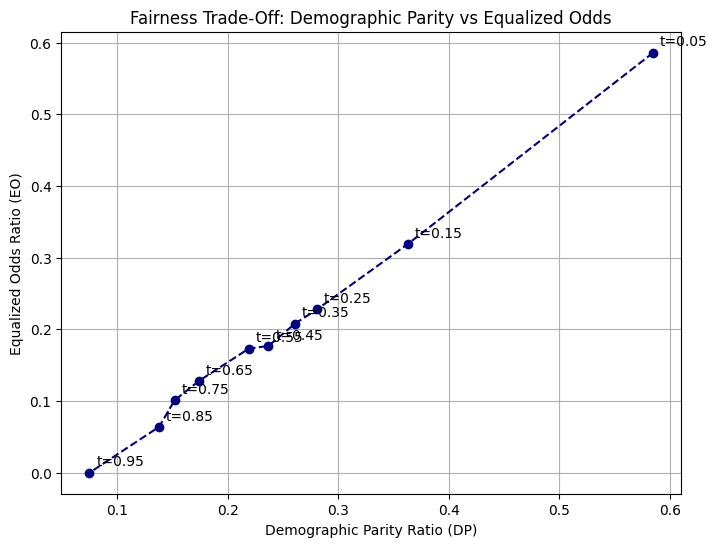

In [7]:
thresholds = np.arange(0.05, 0.96, 0.10)
fairness_results = []

mask_female = (X_test['male'] == 0)
mask_male = (X_test['male'] == 1)

for t in thresholds:
    y_pred_t = (preds_b_raw >= t).astype(int)

    sr_f = y_pred_t[mask_female].mean()
    sr_m = y_pred_t[mask_male].mean()
    dp = sr_f / sr_m if sr_m > 0 else np.nan

    tp_f = np.sum((y_pred_t == 1) & (y_test == 1) & mask_female)
    fn_f = np.sum((y_pred_t == 0) & (y_test == 1) & mask_female)
    fp_f = np.sum((y_pred_t == 1) & (y_test == 0) & mask_female)
    tn_f = np.sum((y_pred_t == 0) & (y_test == 0) & mask_female)

    tp_m = np.sum((y_pred_t == 1) & (y_test == 1) & mask_male)
    fn_m = np.sum((y_pred_t == 0) & (y_test == 1) & mask_male)
    fp_m = np.sum((y_pred_t == 1) & (y_test == 0) & mask_male)
    tn_m = np.sum((y_pred_t == 0) & (y_test == 0) & mask_male)

    tpr_f = tp_f / (tp_f + fn_f) if (tp_f + fn_f) > 0 else 0
    tpr_m = tp_m / (tp_m + fn_m) if (tp_m + fn_m) > 0 else 0

    fpr_f = fp_f / (fp_f + tn_f) if (fp_f + tn_f) > 0 else 0
    fpr_m = fp_m / (fp_m + tn_m) if (fp_m + tn_m) > 0 else 0

    eo = min(tpr_f / tpr_m if tpr_m > 0 else 0, fpr_f / fpr_m if fpr_m > 0 else 0)

    prec_f = tp_f / (tp_f + fp_f) if (tp_f + fp_f) > 0 else 0
    prec_m = tp_m / (tp_m + fp_m) if (tp_m + fp_m) > 0 else 0
    pp = prec_f / prec_m if prec_m > 0 else np.nan

    acc = accuracy_score(y_test, y_pred_t)

    fairness_results.append({
        't': round(t, 2), 'DP': round(dp, 3), 'EO': round(eo, 3), 'PP': round(pp, 3),
        'TPR_F': round(tpr_f, 3), 'TPR_M': round(tpr_m, 3),
        'FPR_F': round(fpr_f, 3), 'FPR_M': round(fpr_m, 3), 'Acc': round(acc, 3)
    })

fairness_df = pd.DataFrame(fairness_results)
print("=== PART 2.4 FAIRNESS TABLE ===")
print(fairness_df.to_string(index=False))

# Plot Trade-off Chart
plt.figure(figsize=(8, 6))
plt.plot(fairness_df['DP'], fairness_df['EO'], marker='o', color='navy', linestyle='--')
for i, row in fairness_df.iterrows():
    plt.annotate(f"t={row['t']}", (row['DP'], row['EO']), textcoords="offset points", xytext=(5,5), ha='left')

plt.title("Fairness Trade-Off: Demographic Parity vs Equalized Odds")
plt.xlabel("Demographic Parity Ratio (DP)")
plt.ylabel("Equalized Odds Ratio (EO)")
plt.grid(True)
plt.savefig("fairness_tradeoff.png", dpi=300, bbox_inches='tight')
plt.show()